# Customer Churn Prediction Using Machine Learning

## Promblem Statement

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
# import requird libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"customer_churn_practice_dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0001,Female,0,No,Yes,65.0,Yes,DSL,Month-to-month,Yes,Bank transfer (automatic),30.85,2020.72,No
1,CUST0002,Male,1,No,No,30.0,Yes,Fiber optic,Month-to-month,No,Credit card (automatic),108.00,3265.76,Yes
2,CUST0003,Male,1,Yes,No,70.0,Yes,Fiber optic,One year,Yes,Bank transfer (automatic),95.32,6608.54,No
3,CUST0004,Female,0,Yes,No,41.0,Yes,DSL,Month-to-month,yes,Bank transfer (automatic),78.76,3166.62,Yes
4,CUST0005,Female,0,No,Yes,28.0,Yes,DSL,Month-to-month,No,Credit card (automatic),74.15,2073.54,No


In [4]:
df.shape

(1008, 14)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'InternetService', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges',
       'Churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        1008 non-null   object 
 1   gender            1000 non-null   object 
 2   SeniorCitizen     1008 non-null   int64  
 3   Partner           1008 non-null   object 
 4   Dependents        1008 non-null   object 
 5   tenure            998 non-null    float64
 6   PhoneService      1008 non-null   object 
 7   InternetService   1008 non-null   object 
 8   Contract          1002 non-null   object 
 9   PaperlessBilling  1008 non-null   object 
 10  PaymentMethod     1008 non-null   object 
 11  MonthlyCharges    1001 non-null   float64
 12  TotalCharges      996 non-null    object 
 13  Churn             1008 non-null   object 
dtypes: float64(2), int64(1), object(11)
memory usage: 110.4+ KB


## Data Cleaning

In [7]:
# check duplicates
df.duplicated().sum()

np.int64(7)

In [8]:
#see duplocates
df[df.duplicated(keep=False)].sort_values("customerID")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
98,CUST0099,Male,1,No,No,17.0,Yes,Fiber optic,One year,Yes,Electronic check,113.96,1900.72,No
1007,CUST0099,Male,1,No,No,17.0,Yes,Fiber optic,One year,Yes,Electronic check,113.96,1900.72,No
217,CUST0218,Female,0,No,No,14.0,Yes,DSL,One year,Yes,Bank transfer (automatic),54.13,702.66,Yes
1003,CUST0218,Female,0,No,No,14.0,Yes,DSL,One year,Yes,Bank transfer (automatic),54.13,702.66,Yes
499,CUST0500,Female,0,No,Yes,14.0,Yes,DSL,One year,Yes,Electronic check,69.93,965.36,No
1001,CUST0500,Female,0,No,Yes,14.0,Yes,DSL,One year,Yes,Electronic check,69.93,965.36,No
786,CUST0787,Female,0,No,No,51.0,Yes,No,Month-to-month,No,Bank transfer (automatic),86.06,4433.72,No
1000,CUST0787,Female,0,No,No,51.0,Yes,No,Month-to-month,No,Bank transfer (automatic),86.06,4433.72,No
803,CUST0804,Male,0,No,No,59.0,Yes,Fiber optic,Month-to-month,Yes,Mailed check,69.27,4107.11,Yes
1004,CUST0804,Male,0,No,No,59.0,Yes,Fiber optic,Month-to-month,Yes,Mailed check,69.27,4107.11,Yes


In [9]:
df=df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
# records with duplicate customer ids
df[df.duplicated(subset="customerID", keep=False)].sort_values("customerID")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
69,CUST0070,Female,0,No,No,51.0,Yes,Fiber optic,month-to-month,No,Bank transfer (automatic),40.46,2070.96,Yes
1005,CUST0070,Female,0,No,No,51.0,Yes,Fiber optic,Month-to-month,No,Bank transfer (automatic),40.46,2070.96,Yes
145,CUST0146,Male,1,Yes,No,22.0,Yes,No,One year,Yes,Bank transfer (automatic),96.36,2126.25,No
146,CUST0146,Female,0,Yes,No,64.0,Yes,No,One year,Yes,Electronic check,28.98,1853.12,No
459,CUST0460,Female,0,No,No,55.0,Yes,DSL,One year,Yes,Bank transfer (automatic),125.00,6898.51,No
460,CUST0460,Male,0,No,No,39.0,Yes,Fiber optic,Month-to-month,No,Mailed check,100.50,3894.14,Yes
606,CUST0607,Female,0,No,No,36.0,Yes,DSL,Two year,Yes,Credit card (automatic),125.00,4516.08,No
607,CUST0607,Male,0,No,No,13.0,Yes,Fiber optic,Month-to-month,No,Electronic check,45.94,610.47,Yes
738,CUST0739,Male,0,Yes,No,48.0,Yes,No,Two year,No,Electronic check,74.96,3601.59,Yes
739,CUST0739,Male,0,No,No,34.0,Yes,Fiber optic,Month-to-month,No,Mailed check,36.02,1189.65,No


In [12]:
# Find the number of unique customer IDs that are repeated e.g IDS=1,2,2,3,1,4  unique-->1,2,3,4 and count will 4
df.loc[
    df.duplicated(subset="customerID", keep=False),
    "customerID"
].nunique()  

6

In [13]:
# Find customer IDs that appear more than once
duplicate_ids = df.loc[
    df.duplicated(subset="customerID", keep=False),
    "customerID"
].unique()
duplicate_ids

array(['CUST0070', 'CUST0146', 'CUST0460', 'CUST0607', 'CUST0739',
       'CUST0862'], dtype=object)

In [14]:
# Count all rows belonging to those IDs
df["customerID"].isin(duplicate_ids).sum()

np.int64(12)

In [15]:
# Check the total number of rows before removing conflicting IDs
print("Rows before cleaning:", len(df))

# Check how many rows belong to the repeated IDs
print("Rows affected:", df["customerID"].isin(duplicate_ids).sum())

Rows before cleaning: 1001
Rows affected: 12


In [16]:
# Remove rows belonging to conflicting customer IDs
df = df[~df["customerID"].isin(duplicate_ids)].copy()
# it will make copy of the records which are not present in duplicate_ids and will store in df.
# Check the number of rows after removal
print("Rows after cleaning:", len(df))

Rows after cleaning: 989


In [17]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0001,Female,0,No,Yes,65.0,Yes,DSL,Month-to-month,Yes,Bank transfer (automatic),30.85,2020.72,No
1,CUST0002,Male,1,No,No,30.0,Yes,Fiber optic,Month-to-month,No,Credit card (automatic),108.00,3265.76,Yes
2,CUST0003,Male,1,Yes,No,70.0,Yes,Fiber optic,One year,Yes,Bank transfer (automatic),95.32,6608.54,No
3,CUST0004,Female,0,Yes,No,41.0,Yes,DSL,Month-to-month,yes,Bank transfer (automatic),78.76,3166.62,Yes
4,CUST0005,Female,0,No,Yes,28.0,Yes,DSL,Month-to-month,No,Credit card (automatic),74.15,2073.54,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,CUST0996,Male,0,No,No,33.0,Yes,Fiber optic,Two year,No,Electronic check,74.02,2353.86,No
996,CUST0997,Male,1,No,No,52.0,Yes,Fiber optic,One year,No,Electronic check,75.82,3928.63,Yes
997,CUST0998,Female,0,Yes,No,24.0,Yes,Fiber optic,Month-to-month,Yes,Mailed check,74.93,1862.74,Yes
998,CUST0999,NaN,0,No,No,9.0,Yes,No,Two year,No,Electronic check,95.07,844.14,No


In [18]:
# check nulls
df.isnull().sum()

customerID           0
gender               8
SeniorCitizen        0
Partner              0
Dependents           0
tenure              10
PhoneService         0
InternetService      0
Contract             6
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       7
TotalCharges        12
Churn                0
dtype: int64

In [19]:
# check unique values in gender col
df["gender"].unique()

array(['Female', 'Male', 'MALE', nan, ' female ', 'Female '], dtype=object)

In [20]:
# remove extra space and standadize capitalization
df['gender']=df["gender"].str.strip().str.capitalize()

#check clean values
df["gender"].unique()
# .str.strip() : remove extra space at the strt and end
# str.capitalize() : changes MALE --> Male

array(['Female', 'Male', nan], dtype=object)

In [21]:
# display unique in Partner col
df["Partner"].unique()

array(['No', 'Yes'], dtype=object)

In [22]:
# display unique in Dependents col
df["Dependents"].unique()

array(['Yes', 'No'], dtype=object)

In [23]:
# display unique in PhoneService col
df["PhoneService"].unique()

array(['Yes', 'No'], dtype=object)

In [24]:
# display unique in InternetService col
df["InternetService"].unique()

array(['DSL', 'Fiber optic', 'No', ' DSL ', 'NO', 'fiber optic'],
      dtype=object)

In [25]:
# remove extra space and standadize capitalization
df['InternetService']=df["InternetService"].str.strip().str.capitalize()

#check clean values
df["InternetService"].unique()

array(['Dsl', 'Fiber optic', 'No'], dtype=object)

In [26]:
# display unique values in contract col
df['Contract'].unique()

array(['Month-to-month', 'One year', 'Two year', nan, 'TWO YEAR',
       ' One year '], dtype=object)

In [27]:
# remove extra space standarizes and capitalization
df['Contract'] = df['Contract'].str.strip().str.capitalize()
df["Contract"].unique()

array(['Month-to-month', 'One year', 'Two year', nan], dtype=object)

In [28]:
# check unique values in PaperlessBilling col
df['PaperlessBilling'].unique()

array(['Yes', 'No', 'yes', 'Yes ', ' NO '], dtype=object)

In [29]:
# remove extra space, standarized and capitaliztion
df['PaperlessBilling']=df['PaperlessBilling'].str.strip().str.capitalize()
df['PaperlessBilling'].unique()

array(['Yes', 'No'], dtype=object)

In [30]:
# display unique values for PaymentMethod col
df['PaymentMethod'].unique()

array(['Bank transfer (automatic)', 'Credit card (automatic)',
       'Mailed check', 'Electronic check', '   '], dtype=object)

In [31]:
# remove extra space from payment method
df['PaymentMethod'] = df['PaymentMethod'].str.strip()

# convert blank space into missing values
df['PaymentMethod'] = df['PaymentMethod'].replace("",np.nan)

#check after cleanin
df['PaymentMethod'].unique()

array(['Bank transfer (automatic)', 'Credit card (automatic)',
       'Mailed check', 'Electronic check', nan], dtype=object)

In [32]:
# dispay datatypes of TotalCharges
df['TotalCharges'].dtype

dtype('O')

In [33]:
#disp some unique values
df['TotalCharges'].unique()[:15]

array(['2020.72', '3265.76', '6608.54', '3166.62', '2073.54', '0.0',
       '4432.61', '4651.35', '5719.77', '3142.44', '177.98', '3659.46',
       '3535.96', '2138.18', '3060.42'], dtype=object)

In [34]:
# convert values tempararil to numric to identify invalid entries
total_charge_numeric = pd.to_numeric(df['TotalCharges'], errors="coerce")
# pd.to_numeric() tries to convert the values into numbers.
# errors="coerce" temporarily turns invalid text into missing values (NaN).

In [35]:
#count values thet could not be converted
total_charge_numeric.isnull().sum()

np.int64(21)

In [36]:
# disp rows with missing or invalid TotalCharges values
df[total_charge_numeric.isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
71,CUST0072,Female,1,No,No,58.0,Yes,Dsl,Month-to-month,Yes,Electronic check,81.53,,No
108,CUST0109,Female,0,Yes,No,20.0,No,Fiber optic,Month-to-month,No,Electronic check,67.24,,Yes
117,CUST0118,Female,0,No,No,45.0,Yes,Fiber optic,Month-to-month,Yes,Bank transfer (automatic),20.10,,No
125,CUST0126,Male,0,No,No,66.0,Yes,Dsl,Month-to-month,Yes,Credit card (automatic),66.03,NaN,No
150,CUST0151,Male,0,Yes,No,43.0,Yes,Fiber optic,Two year,Yes,Bank transfer (automatic),18.00,,No
181,CUST0182,Female,0,No,No,58.0,Yes,Fiber optic,Month-to-month,No,Mailed check,36.73,NaN,No
269,CUST0270,Male,0,No,No,42.0,Yes,Fiber optic,Month-to-month,Yes,Mailed check,85.98,NaN,No
270,CUST0271,Female,0,No,Yes,22.0,No,No,Month-to-month,Yes,Credit card (automatic),92.30,NaN,Yes
381,CUST0382,Male,0,No,Yes,2.0,Yes,Fiber optic,Two year,Yes,Mailed check,66.52,unknown,Yes
390,CUST0391,Male,0,Yes,Yes,72.0,Yes,Fiber optic,Month-to-month,No,Electronic check,28.31,NaN,No


In [37]:
# convert TotalCharges into numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors="coerce"
)
# check the data type 
df['TotalCharges'].dtype

dtype('float64')

In [38]:
df.TotalCharges.isnull().sum()

np.int64(21)

In [39]:
# check datatype for tenure column
df['tenure'].dtype

dtype('float64')

In [40]:
# check min and max values
print(df['tenure'].min())
print(df['tenure'].max())

0.0
150.0


In [41]:
# check missing values
df['tenure'].isnull().sum()

np.int64(10)

In [42]:
df[df['tenure']>72]
#tenuere is number of months that the customers use company service
# This code shows customers whose tenure is above 72 months,
#so we can inspect those records before deciding how to handle them.
#We checked this because the standard Telco Customer Churn dataset uses a tenure range of 0–72 months. Values above 72 deserve investigation.

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
287,CUST0288,Male,0,No,No,150.0,Yes,Fiber optic,Two year,No,Electronic check,56.96,736.98,Yes


In [43]:
# check datatype for MonthlyCharges
df['MonthlyCharges'].dtype

dtype('float64')

In [44]:
df['MonthlyCharges'].min()

0.0

In [45]:
df['MonthlyCharges'].max()

999.99

In [46]:
df['MonthlyCharges'].isnull().sum()

np.int64(7)

In [47]:
# find row of monthlyCharge is greater than 200 because 
# max of MonthlyCharges is 999.99 which is very high so to see more like this do
df[df['MonthlyCharges']>200]
# If the minimum is 0 and the maximum is 999.99, we should investigate these values. A charge of 999.99 might be an incorrect or unusual value.

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
166,CUST0167,Female,0,No,No,43.0,Yes,Fiber optic,One year,No,Bank transfer (automatic),999.99,810.03,Yes


In [48]:
# now check unique values/ categoris of target variable
df['Churn'].unique()

array(['No', 'Yes'], dtype=object)

In [49]:
# check count for each category
df['Churn'].value_counts()

Churn
No     744
Yes    245
Name: count, dtype: int64

In [50]:
# this is class imbalence

In [51]:
# check missing values in target variable
df['Churn'].isnull().sum()

np.int64(0)

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 989 entries, 0 to 999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        989 non-null    object 
 1   gender            981 non-null    object 
 2   SeniorCitizen     989 non-null    int64  
 3   Partner           989 non-null    object 
 4   Dependents        989 non-null    object 
 5   tenure            979 non-null    float64
 6   PhoneService      989 non-null    object 
 7   InternetService   989 non-null    object 
 8   Contract          983 non-null    object 
 9   PaperlessBilling  989 non-null    object 
 10  PaymentMethod     985 non-null    object 
 11  MonthlyCharges    982 non-null    float64
 12  TotalCharges      968 non-null    float64
 13  Churn             989 non-null    object 
dtypes: float64(3), int64(1), object(10)
memory usage: 115.9+ KB


In [53]:
df.isnull().sum()

customerID           0
gender               8
SeniorCitizen        0
Partner              0
Dependents           0
tenure              10
PhoneService         0
InternetService      0
Contract             6
PaperlessBilling     0
PaymentMethod        4
MonthlyCharges       7
TotalCharges        21
Churn                0
dtype: int64

In [54]:
# fill the missing values
df['gender']=df['gender'].fillna(df['gender'].mode()[0])
df['tenure']=df['tenure'].fillna(df['tenure'].median())
df['Contract']=df['Contract'].fillna(df['Contract'].mode()[0])
df['PaymentMethod']=df['PaymentMethod'].fillna(df['PaymentMethod'].mode()[0])
df['MonthlyCharges']=df['MonthlyCharges'].fillna(df['MonthlyCharges'].median())
df['TotalCharges']=df['TotalCharges'].fillna(df['TotalCharges'].median())

In [55]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
InternetService     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## EDA

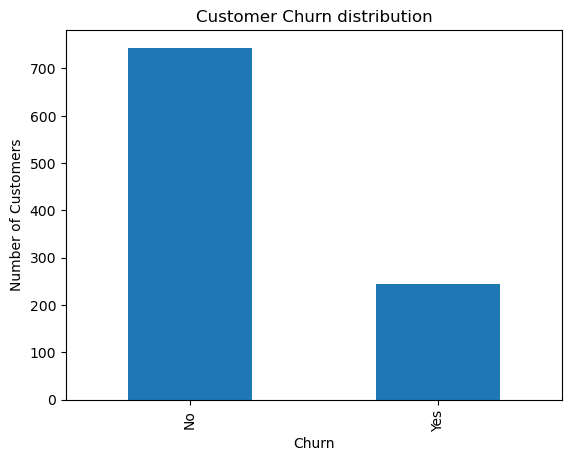

In [56]:
# plot for number of customer in eact category
df['Churn'].value_counts().plot(kind="bar")
plt.title("Customer Churn distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

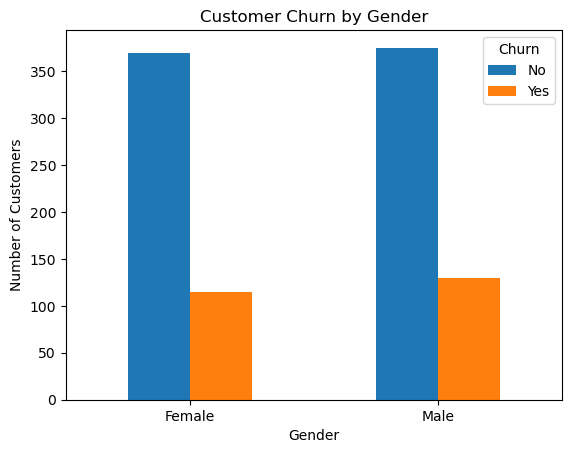

In [57]:
# Customer Churn by Gender
pd.crosstab(df["gender"], df["Churn"]).plot(kind="bar")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

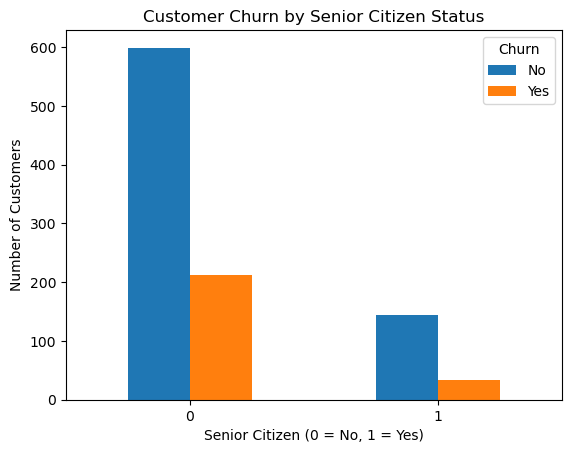

In [58]:
# Analyze Churn by Senior Citizen Status
pd.crosstab(df["SeniorCitizen"], df["Churn"]).plot(kind="bar")

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

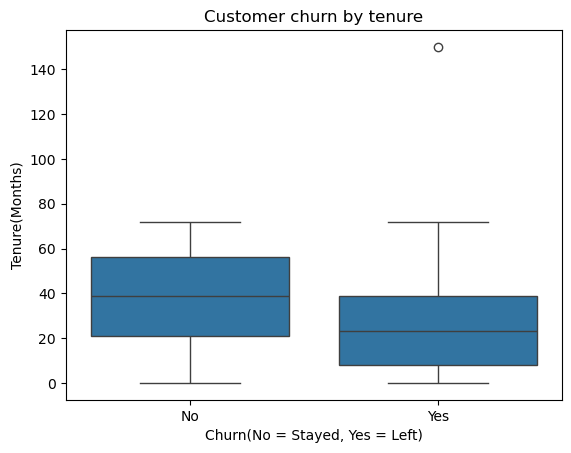

In [59]:
#compare churn across tenure
sns.boxplot(x='Churn',y='tenure',data=df)
plt.title("Customer churn by tenure")
plt.xlabel("Churn(No = Stayed, Yes = Left)")
plt.ylabel("Tenure(Months)")
plt.show()

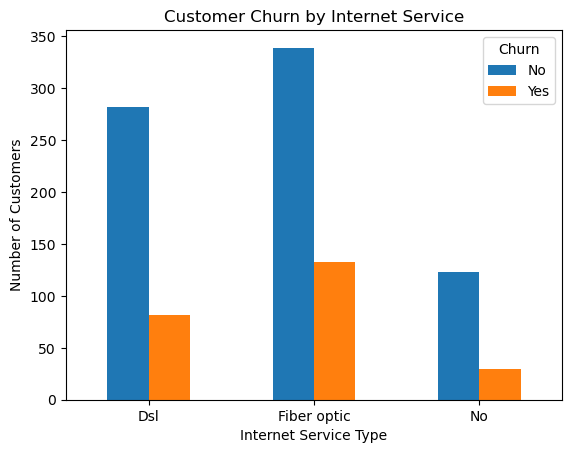

In [60]:
# analyze churn by internet service
pd.crosstab(df['InternetService'],df['Churn']).plot(kind='bar')
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

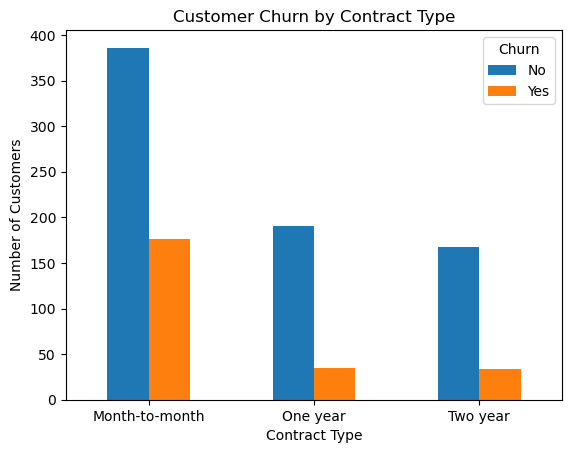

In [61]:
# Compare churn across contract types
pd.crosstab(df["Contract"], df["Churn"]).plot(kind="bar")
# pd.crosstab() counts customers for each combination of contract type and churn.
# e.g month-month&churn(yes or not) 1year&churn(yes or not) 2years&churn(yes or not)
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)    # Keeps X-axis labels straight.     
plt.legend(title="Churn")   # Shows what the graph's colors represent.
plt.show()

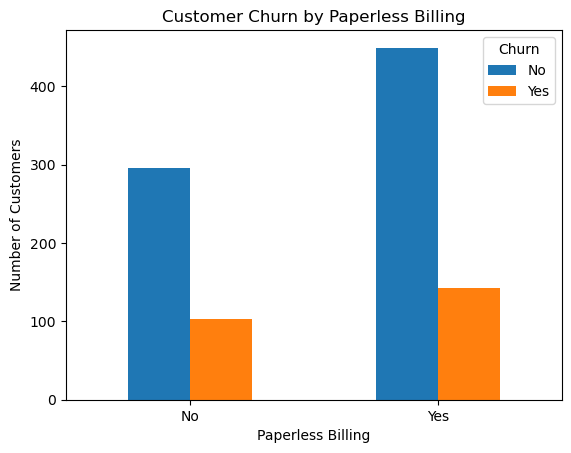

In [62]:
# Analyze Churn by Paperless Billing
pd.crosstab(df["PaperlessBilling"], df["Churn"]).plot(kind="bar")

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

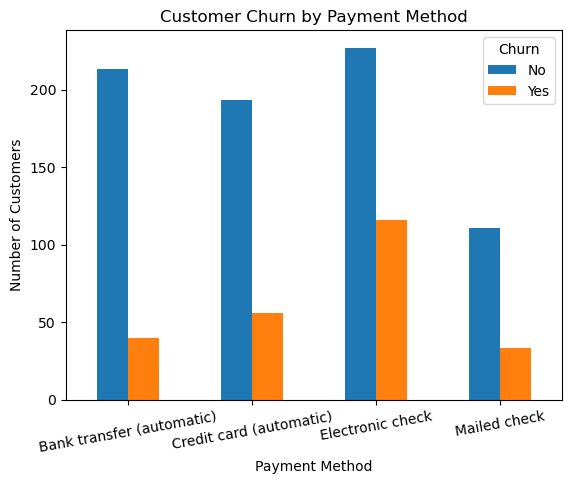

In [63]:
# Analyze Churn by Payment Method
pd.crosstab(df["PaymentMethod"], df["Churn"]).plot(kind="bar")

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)
plt.legend(title="Churn")
plt.show()

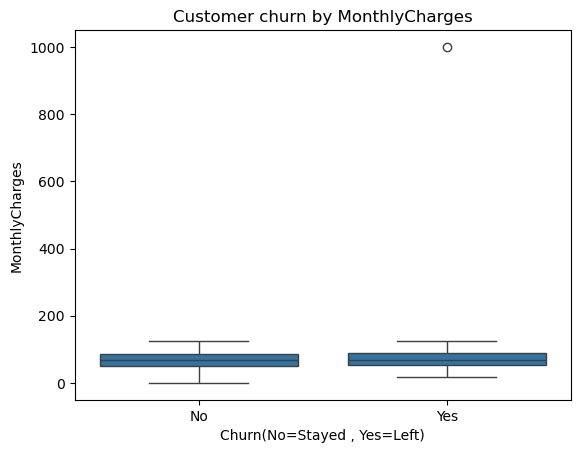

In [64]:
# analyze change by MonthlyCharge
sns.boxplot(x='Churn',y='MonthlyCharges',data=df)
plt.title('Customer churn by MonthlyCharges')
plt.xlabel('Churn(No=Stayed , Yes=Left)')
plt.ylabel('MonthlyCharges')
plt.show()

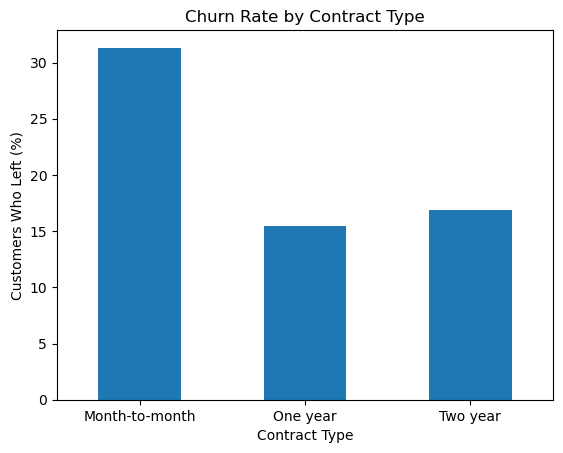

In [65]:
# Customer Churn by Contract Type — Churn Percentage
churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

churn_rate["Yes"].plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customers Who Left (%)")
plt.xticks(rotation=0)
plt.show()

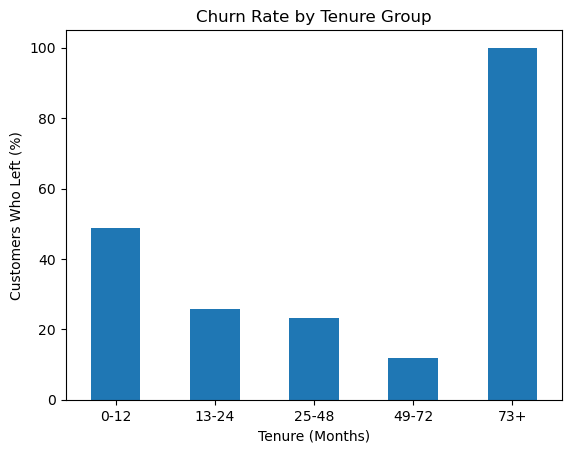

In [66]:
# Customer Churn Rate by Tenure Group
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72, float("inf")],
    labels=["0-12", "13-24", "25-48", "49-72", "73+"]
)

tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure (Months)")
plt.ylabel("Customers Who Left (%)")
plt.xticks(rotation=0)
plt.show()


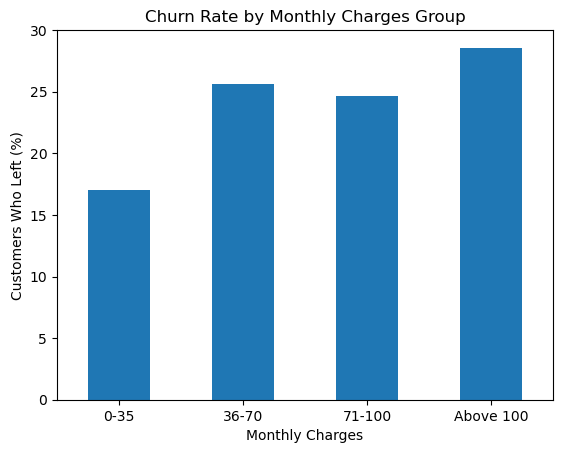

In [67]:
# Customer Churn Rate by Monthly Charges Group
df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[-1, 35, 70, 100, float("inf")],
    labels=["0-35", "36-70", "71-100", "Above 100"]
)

charges_churn = pd.crosstab(
    df["MonthlyChargesGroup"],
    df["Churn"],
    normalize="index"
) * 100

charges_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Monthly Charges Group")
plt.xlabel("Monthly Charges")
plt.ylabel("Customers Who Left (%)")
plt.xticks(rotation=0)
plt.show()

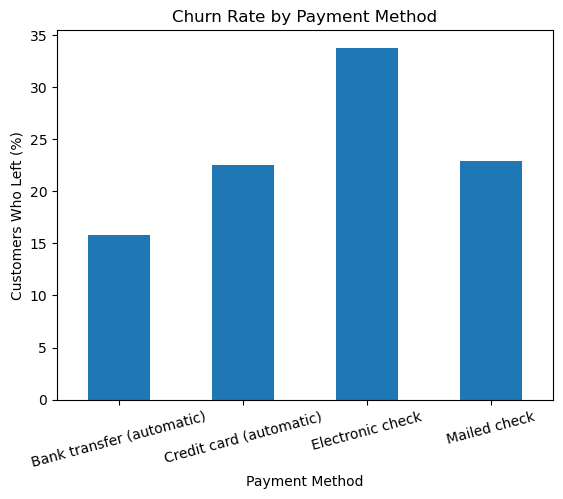

In [68]:
# Customer Churn Rate by payment Method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Customers Who Left (%)")
plt.xticks(rotation=15)
plt.show()


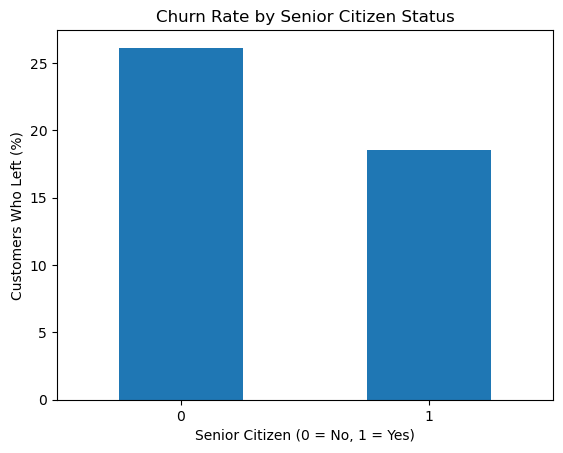

In [69]:
# Customer Churn Rate by Senior Citizen Status
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Customers Who Left (%)")
plt.xticks(rotation=0)
plt.show()

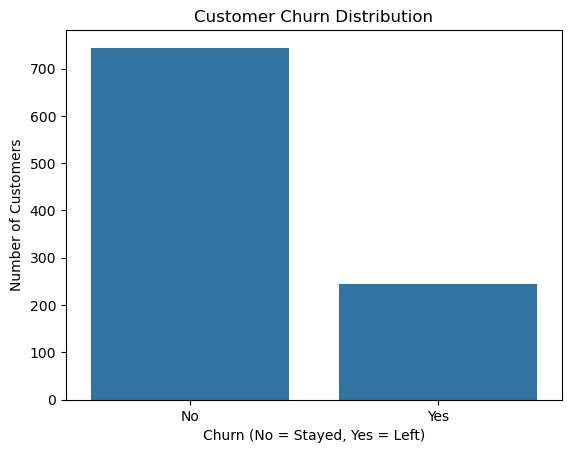

In [70]:
# Customer Churn Distribution
sns.countplot(x="Churn", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (No = Stayed, Yes = Left)")
plt.ylabel("Number of Customers")
plt.show()

In [71]:
from sklearn.preprocessing import LabelEncoder 
le = LabelEncoder()

In [72]:
df[df.select_dtypes(include='object').columns]

,customerID,gender,Partner,Dependents,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,Churn
0,CUST0001,Female,No,Yes,Yes,Dsl,Month-to-month,Yes,Bank transfer (automatic),No
1,CUST0002,Male,No,No,Yes,Fiber optic,Month-to-month,No,Credit card (automatic),Yes
2,CUST0003,Male,Yes,No,Yes,Fiber optic,One year,Yes,Bank transfer (automatic),No
3,CUST0004,Female,Yes,No,Yes,Dsl,Month-to-month,Yes,Bank transfer (automatic),Yes
4,CUST0005,Female,No,Yes,Yes,Dsl,Month-to-month,No,Credit card (automatic),No
...,...,...,...,...,...,...,...,...,...,...
995,CUST0996,Male,No,No,Yes,Fiber optic,Two year,No,Electronic check,No
996,CUST0997,Male,No,No,Yes,Fiber optic,One year,No,Electronic check,Yes
997,CUST0998,Female,Yes,No,Yes,Fiber optic,Month-to-month,Yes,Mailed check,Yes
998,CUST0999,Male,No,No,Yes,No,Two year,No,Electronic check,No


In [73]:
from sklearn.preprocessing import LabelEncoder

categorical_columns = [
    'gender', 'Partner', 'Dependents', 'PhoneService',
    'InternetService', 'Contract', 'PaperlessBilling',
    'PaymentMethod', 'Churn'
]

label_encoders = {}

for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

    print(f"{col} mapping:",
          dict(zip(le.classes_, le.transform(le.classes_))))
    
df['customerID'] = range(1, len(df)+1)

gender mapping: {'Female': np.int64(0), 'Male': np.int64(1)}
Partner mapping: {'No': np.int64(0), 'Yes': np.int64(1)}
Dependents mapping: {'No': np.int64(0), 'Yes': np.int64(1)}
PhoneService mapping: {'No': np.int64(0), 'Yes': np.int64(1)}
InternetService mapping: {'Dsl': np.int64(0), 'Fiber optic': np.int64(1), 'No': np.int64(2)}
Contract mapping: {'Month-to-month': np.int64(0), 'One year': np.int64(1), 'Two year': np.int64(2)}
PaperlessBilling mapping: {'No': np.int64(0), 'Yes': np.int64(1)}
PaymentMethod mapping: {'Bank transfer (automatic)': np.int64(0), 'Credit card (automatic)': np.int64(1), 'Electronic check': np.int64(2), 'Mailed check': np.int64(3)}
Churn mapping: {'No': np.int64(0), 'Yes': np.int64(1)}


In [74]:
#df[df.select_dtypes(include='object').columns] = df[df.select_dtypes(include='object').columns].apply(le.fit_transform)

In [75]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,MonthlyChargesGroup
0,1,0,0,0,1,65.0,1,0,0,1,0,30.85,2020.72,0,49-72,0-35
1,2,1,1,0,0,30.0,1,1,0,0,1,108.00,3265.76,1,25-48,Above 100
2,3,1,1,1,0,70.0,1,1,1,1,0,95.32,6608.54,0,49-72,71-100
3,4,0,0,1,0,41.0,1,0,0,1,0,78.76,3166.62,1,25-48,71-100
4,5,0,0,0,1,28.0,1,0,0,0,1,74.15,2073.54,0,25-48,71-100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,985,1,0,0,0,33.0,1,1,2,0,2,74.02,2353.86,0,25-48,71-100
996,986,1,1,0,0,52.0,1,1,1,0,2,75.82,3928.63,1,49-72,71-100
997,987,0,0,1,0,24.0,1,1,0,1,3,74.93,1862.74,1,13-24,71-100
998,988,1,0,0,0,9.0,1,2,2,0,2,95.07,844.14,0,0-12,71-100


In [76]:
df=df.drop(columns=['TenureGroup','MonthlyChargesGroup'])

In [77]:
df1=df # just for backup

In [78]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,0,0,0,1,65.0,1,0,0,1,0,30.85,2020.72,0
1,2,1,1,0,0,30.0,1,1,0,0,1,108.00,3265.76,1
2,3,1,1,1,0,70.0,1,1,1,1,0,95.32,6608.54,0
3,4,0,0,1,0,41.0,1,0,0,1,0,78.76,3166.62,1
4,5,0,0,0,1,28.0,1,0,0,0,1,74.15,2073.54,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,985,1,0,0,0,33.0,1,1,2,0,2,74.02,2353.86,0
996,986,1,1,0,0,52.0,1,1,1,0,2,75.82,3928.63,1
997,987,0,0,1,0,24.0,1,1,0,1,3,74.93,1862.74,1
998,988,1,0,0,0,9.0,1,2,2,0,2,95.07,844.14,0


In [109]:
# Separate input features (X) and target (y)
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

In [81]:
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,0,0,0,1,65.0,1,0,0,1,0,30.85,2020.72
1,1,1,0,0,30.0,1,1,0,0,1,108.00,3265.76
2,1,1,1,0,70.0,1,1,1,1,0,95.32,6608.54
3,0,0,1,0,41.0,1,0,0,1,0,78.76,3166.62
4,0,0,0,1,28.0,1,0,0,0,1,74.15,2073.54
...,...,...,...,...,...,...,...,...,...,...,...,...
995,1,0,0,0,33.0,1,1,2,0,2,74.02,2353.86
996,1,1,0,0,52.0,1,1,1,0,2,75.82,3928.63
997,0,0,1,0,24.0,1,1,0,1,3,74.93,1862.74
998,1,0,0,0,9.0,1,2,2,0,2,95.07,844.14


In [82]:
y

0      0
1      1
2      0
3      1
4      0
      ..
995    0
996    1
997    1
998    0
999    0
Name: Churn, Length: 989, dtype: int64

In [83]:
from sklearn.model_selection import train_test_split 
churn_train,churn_test=train_test_split(df,test_size=0.2,random_state=42)

In [84]:
churn_train.Churn.value_counts()

Churn
0    595
1    196
Name: count, dtype: int64

In [85]:
#class imbalance
# over sampling
c1=churn_train[churn_train.Churn==1]
churn_train=pd.concat([churn_train,c1,c1])
churn_train.shape

(1183, 14)

In [86]:
churn_train.Churn.value_counts()

Churn
0    595
1    588
Name: count, dtype: int64

In [87]:
churn_train_x=churn_train.drop(columns=['customerID','Churn'])
churn_train_y=churn_train['Churn']

churn_test_x=churn_test.drop(columns=['customerID','Churn'])
churn_test_y=churn_test['Churn']

In [88]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()

In [89]:
lr.fit(churn_train_x,churn_train_y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [90]:
pred_train=lr.predict(churn_train_x)
pred_test=lr.predict(churn_test_x)

In [91]:
from sklearn.metrics import confusion_matrix
mat_test=confusion_matrix(churn_test_y,pred_test)

In [92]:
mat_test

array([[97, 52],
       [18, 31]])

In [93]:
52/(52+97)*100  #False Positive rate 

34.899328859060404

In [94]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score

In [95]:
accuracy_score(churn_test_y,pred_test)

0.6464646464646465

In [96]:
recall_score(churn_test_y,pred_test)

0.6326530612244898

In [97]:
precision_score(churn_test_y,pred_test)

0.37349397590361444

In [98]:
f1_score(churn_test_y,pred_test)

0.4696969696969697

In [99]:
pred_prob_test=lr.predict_proba(churn_test_x)
len(pred_prob_test)

198

In [100]:
from sklearn.metrics import roc_auc_score,roc_curve

In [101]:
roc_auc_score(churn_test_y,pred_prob_test[:,1])

0.7042870839611012

In [102]:
fpr,tpr,thre=roc_curve(churn_test_y,pred_prob_test[:,1])

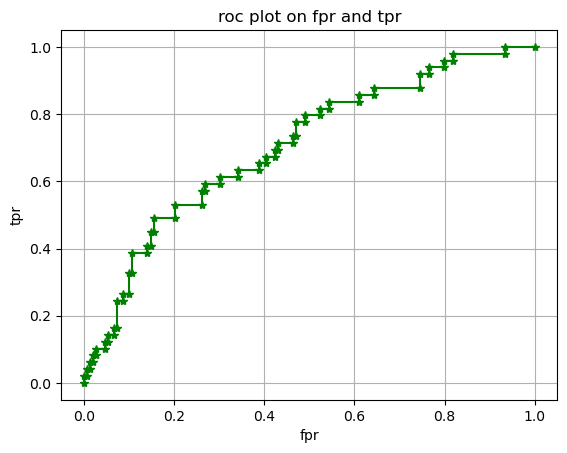

In [103]:
plt.plot(fpr,tpr,marker='*',color='green')
plt.xlabel('fpr')
plt.ylabel('tpr')
plt.title('roc plot on fpr and tpr')
plt.grid()

In [104]:
import pickle
with open("model.pkl","wb") as file:
    pickle.dump(lr,file)

In [105]:
churn_train_x.columns.tolist()
print("Number of input features :",lr.n_features_in_)

Number of input features : 12


In [106]:
churn_train_x.columns.tolist()

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'InternetService',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges']

In [107]:
import pickle
with open("feature_columns.pkl","wb") as file:
    pickle.dump(churn_train_x.columns.tolist(),file)

In [108]:
df.dtypes

customerID            int64
gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure              float64
PhoneService          int64
InternetService       int64
Contract              int64
PaperlessBilling      int64
PaymentMethod         int64
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object